In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import time
from numpy.random import default_rng

from sklearn.linear_model import (
    LinearRegression,  
    Ridge,              
    Lasso,              
    SGDRegressor,       
)
from sklearn.model_selection import (
    train_test_split,   
    GridSearchCV,      
    cross_val_score,    
    KFold,              
)
from sklearn.preprocessing import (
    StandardScaler,       
    PolynomialFeatures,     
)
from sklearn.pipeline import Pipeline   
from sklearn.metrics import mean_squared_error

matplotlib.rcParams['figure.dpi'] = 120
rng = default_rng(42)   

print('All imports ready.')


All imports ready.


In [ ]:
x_D1 = rng.normal(loc=1.0, scale=0.05, size=(100, 1))

psi = rng.normal(loc=0.0, scale=1.0, size=(100, 1))

y_D1 = 1.3 * x_D1**2 + 4.8 * x_D1 + 8 + psi

print(f'x shape: {x_D1.shape}')
print(f'y shape: {y_D1.shape}')
print(f'x range: [{x_D1.min():.3f}, {x_D1.max():.3f}]   ← tightly packed around 1')
print(f'y range: [{y_D1.min():.3f}, {y_D1.max():.3f}]')
print(f'\nFirst 5 rows:')
for i in range(5):
    print(f'  x={x_D1[i,0]:.4f}  →  y={y_D1[i,0]:.4f}')


x shape: (100, 1)
y shape: (100, 1)
x range: [0.902, 1.107]   ← tightly packed around 1
y range: [11.723, 17.256]

First 5 rows:
  x=1.0152  →  y=13.8349
  x=0.9480  →  y=15.0179
  x=1.0375  →  y=14.0232
  x=1.0470  →  y=15.1884
  x=0.9024  →  y=12.4569


In [ ]:
wine = pd.read_csv('wine+quality/winequality-red.csv', sep=';')

print(f'Shape: {wine.shape}')
print(f'NaN count: {wine.isna().sum().sum()}')
print(f'Target (quality) range: {wine["quality"].min()} – {wine["quality"].max()}')
print(f'Quality distribution:')
print(wine['quality'].value_counts().sort_index())
wine.head(3)


Shape: (1599, 12)
NaN count: 0
Target (quality) range: 3 – 8
Quality distribution:
3     10
4     53
5    681
6    638
7    199
8     18
Name: quality, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5


In [ ]:
X_wine = wine.drop(columns='quality').to_numpy()  
y_wine = wine['quality'].to_numpy()                

X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)  
X_test  = scaler.transform(X_test)        

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')
print(f'Train quality mean: {y_train.mean():.3f}  |  Test quality mean: {y_test.mean():.3f}')
print(f'\nAfter normalization — feature means (should be ≈ 0):')
print(np.round(X_train.mean(axis=0), 3))
print(f'Feature stds (should be ≈ 1):')
print(np.round(X_train.std(axis=0), 3))


Train: (1279, 11)  |  Test: (320, 11)
Train quality mean: 5.624  |  Test quality mean: 5.684

After normalization — feature means (should be ≈ 0):
[ 0. -0.  0. -0.  0. -0. -0.  0.  0.  0.  0.]
Feature stds (should be ≈ 1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:

print('=== Exercise 1, Question 2: Train/Test RMSE ===\n')

ols_etas  = [0.1, 0.01, 0.001]
ols_train = []
ols_test  = []

for eta in ols_etas:
    m = SGDRegressor(penalty=None, learning_rate='constant', eta0=eta,
                     max_iter=1000, random_state=42, tol=1e-4)
    m.fit(X_train, y_train)
    ols_train.append(np.sqrt(mean_squared_error(y_train, m.predict(X_train))))
    ols_test.append( np.sqrt(mean_squared_error(y_test,  m.predict(X_test))))
    print(f'  OLS   eta={eta:.3f}  → Train RMSE: {ols_train[-1]:.4f}  Test RMSE: {ols_test[-1]:.4f}')

print()


ridge_alphas = [0.0001, 1.0, 100.0]
ridge_train  = []
ridge_test   = []

for alpha in ridge_alphas:
    m = SGDRegressor(penalty='l2', alpha=alpha,
                     max_iter=1000, random_state=42, tol=1e-4)
    m.fit(X_train, y_train)
    ridge_train.append(np.sqrt(mean_squared_error(y_train, m.predict(X_train))))
    ridge_test.append( np.sqrt(mean_squared_error(y_test,  m.predict(X_test))))
    print(f'  Ridge alpha={alpha:.4f}  → Train RMSE: {ridge_train[-1]:.4f}  Test RMSE: {ridge_test[-1]:.4f}')

print()

lasso_alphas = [0.0001, 0.1, 1.0]
lasso_train  = []
lasso_test   = []

for alpha in lasso_alphas:
    m = SGDRegressor(penalty='l1', alpha=alpha,
                     max_iter=1000, random_state=42, tol=1e-4)
    m.fit(X_train, y_train)
    lasso_train.append(np.sqrt(mean_squared_error(y_train, m.predict(X_train))))
    lasso_test.append( np.sqrt(mean_squared_error(y_test,  m.predict(X_test))))
    print(f'  LASSO alpha={alpha:.4f}  → Train RMSE: {lasso_train[-1]:.4f}  Test RMSE: {lasso_test[-1]:.4f}')


=== Exercise 1, Question 2: Train/Test RMSE ===

  OLS   eta=0.100  → Train RMSE: 67017803.4214  Test RMSE: 53692159.8056
  OLS   eta=0.010  → Train RMSE: 0.6548  Test RMSE: 0.6323
  OLS   eta=0.001  → Train RMSE: 0.6521  Test RMSE: 0.6285

  Ridge alpha=0.0001  → Train RMSE: 0.6515  Test RMSE: 0.6250
  Ridge alpha=1.0000  → Train RMSE: 0.6850  Test RMSE: 0.6738
  Ridge alpha=100.0000  → Train RMSE: 0.8010  Test RMSE: 0.8042

  LASSO alpha=0.0001  → Train RMSE: 0.6515  Test RMSE: 0.6251
  LASSO alpha=0.1000  → Train RMSE: 0.6798  Test RMSE: 0.6615
  LASSO alpha=1.0000  → Train RMSE: 0.8066  Test RMSE: 0.8103


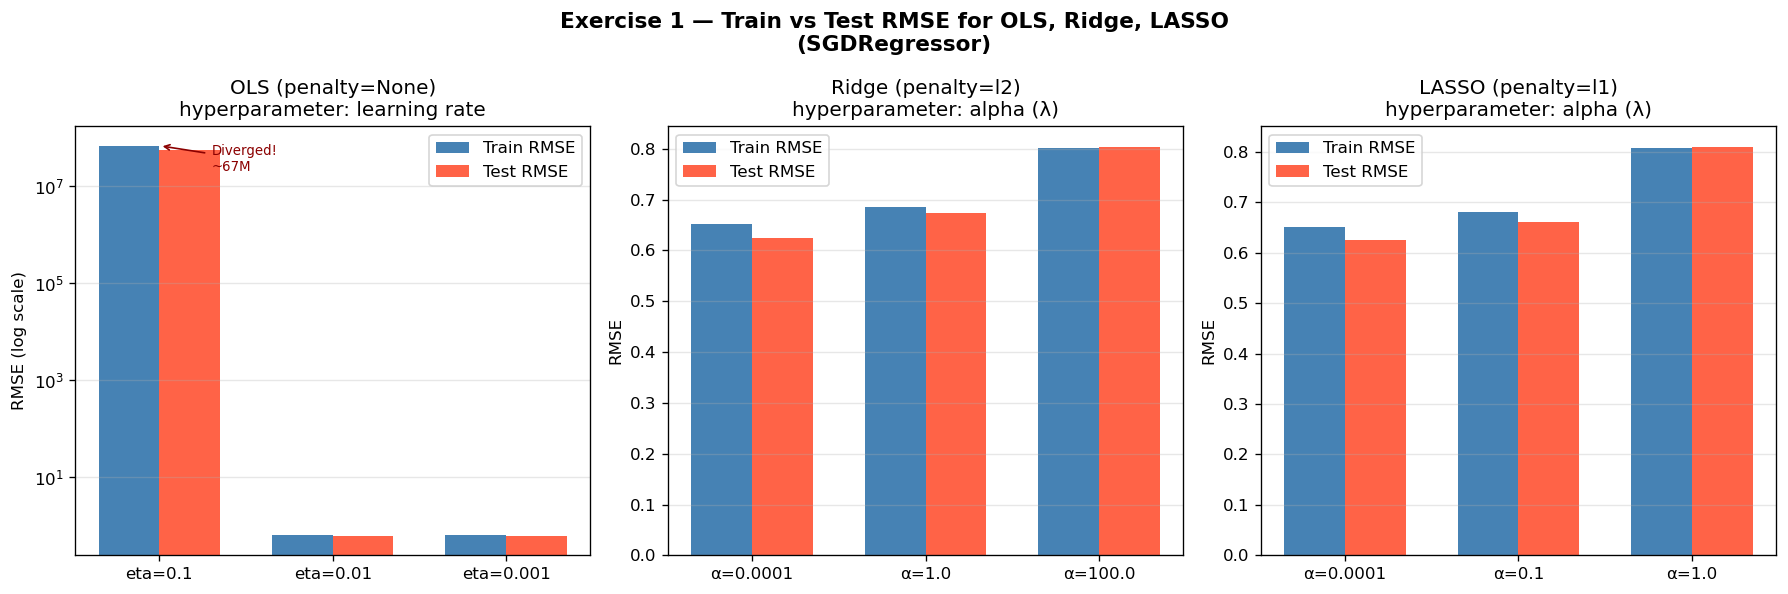

Saved: fig_ex1_glm_rmse.png


In [ ]:


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Exercise 1 — Train vs Test RMSE for OLS, Ridge, LASSO\n(SGDRegressor)',
             fontsize=13, fontweight='bold')

x_pos   = np.arange(3)    
width   = 0.35             


ax = axes[0]
ax.bar(x_pos - width/2, ols_train, width, label='Train RMSE', color='steelblue')
ax.bar(x_pos + width/2, ols_test,  width, label='Test RMSE',  color='tomato')
ax.set_yscale('log')                          
ax.set_xticks(x_pos)
ax.set_xticklabels([f'eta={e}' for e in ols_etas])
ax.set_title('OLS (penalty=None)\nhyperparameter: learning rate')
ax.set_ylabel('RMSE (log scale)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.annotate('Diverged!\n~67M', xy=(0, ols_train[0]),
            xytext=(0.3, ols_train[0] * 0.3),
            fontsize=8, color='darkred',
            arrowprops=dict(arrowstyle='->', color='darkred'))


ax = axes[1]
ax.bar(x_pos - width/2, ridge_train, width, label='Train RMSE', color='steelblue')
ax.bar(x_pos + width/2, ridge_test,  width, label='Test RMSE',  color='tomato')
ax.set_xticks(x_pos)
ax.set_xticklabels([f'α={a}' for a in ridge_alphas])
ax.set_title('Ridge (penalty=l2)\nhyperparameter: alpha (λ)')
ax.set_ylabel('RMSE')
ax.legend()
ax.grid(axis='y', alpha=0.3)

ax = axes[2]
ax.bar(x_pos - width/2, lasso_train, width, label='Train RMSE', color='steelblue')
ax.bar(x_pos + width/2, lasso_test,  width, label='Test RMSE',  color='tomato')
ax.set_xticks(x_pos)
ax.set_xticklabels([f'α={a}' for a in lasso_alphas])
ax.set_title('LASSO (penalty=l1)\nhyperparameter: alpha (λ)')
ax.set_ylabel('RMSE')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('fig_ex1_glm_rmse.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_ex1_glm_rmse.png')


OLS  best eta=0.0001  CV RMSE=0.6614
Ridge best alpha=0.1  CV RMSE=0.6599
LASSO best alpha=0.001  CV RMSE=0.6609


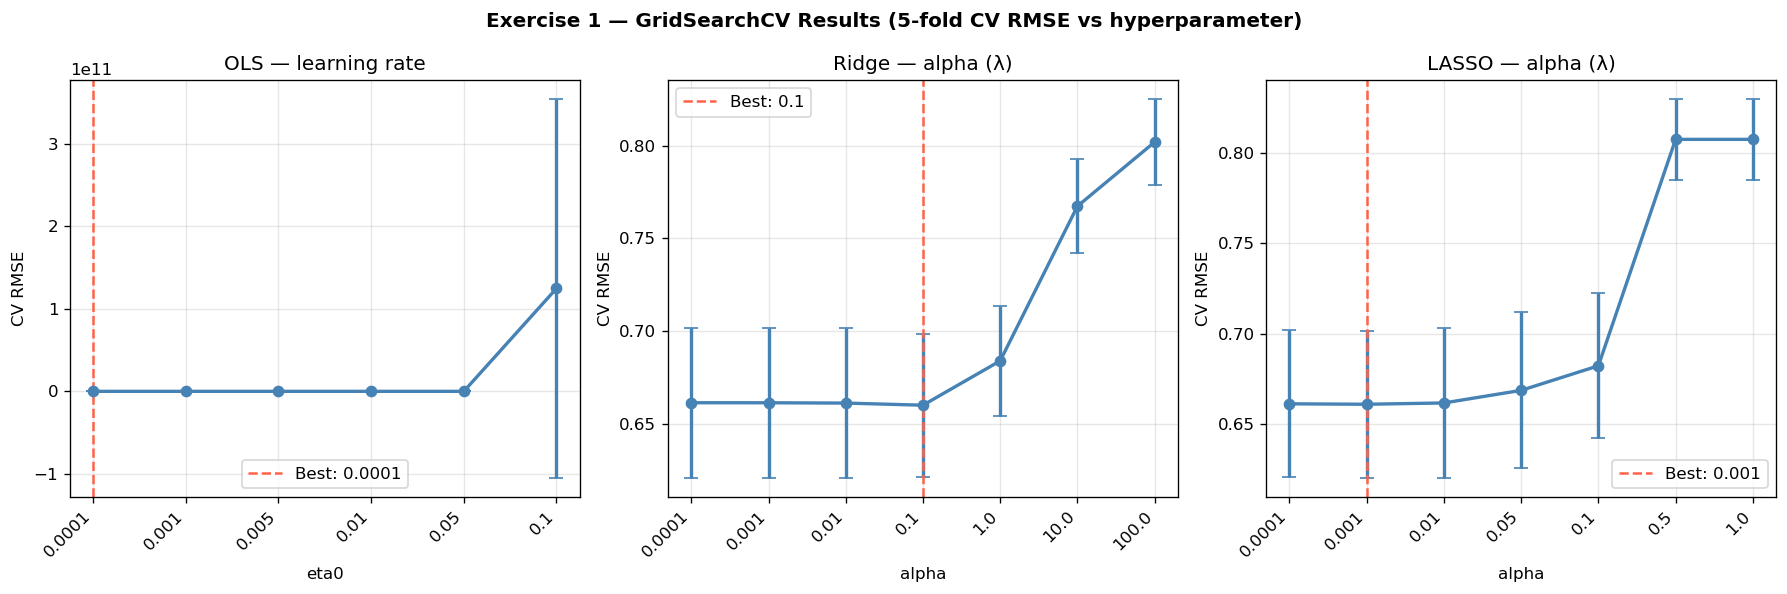

Saved: fig_ex1_gridsearch.png


In [ ]:
ols_eta_grid   = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1]
ridge_alpha_grid = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lasso_alpha_grid = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0]

gs_ols = GridSearchCV(
    SGDRegressor(penalty=None, learning_rate='constant',
                 max_iter=1000, random_state=42, tol=1e-4),
    param_grid={'eta0': ols_eta_grid},
    cv=5,
    scoring='neg_root_mean_squared_error'
)
gs_ols.fit(X_train, y_train)
best_eta = gs_ols.best_params_['eta0']
print(f'OLS  best eta={best_eta}  CV RMSE={-gs_ols.best_score_:.4f}')

gs_ridge = GridSearchCV(
    SGDRegressor(penalty='l2', max_iter=1000, random_state=42, tol=1e-4),
    param_grid={'alpha': ridge_alpha_grid},
    cv=5,
    scoring='neg_root_mean_squared_error'
)
gs_ridge.fit(X_train, y_train)
best_alpha_ridge = gs_ridge.best_params_['alpha']
print(f'Ridge best alpha={best_alpha_ridge}  CV RMSE={-gs_ridge.best_score_:.4f}')


gs_lasso = GridSearchCV(
    SGDRegressor(penalty='l1', max_iter=1000, random_state=42, tol=1e-4),
    param_grid={'alpha': lasso_alpha_grid},
    cv=5,
    scoring='neg_root_mean_squared_error'
)
gs_lasso.fit(X_train, y_train)
best_alpha_lasso = gs_lasso.best_params_['alpha']
print(f'LASSO best alpha={best_alpha_lasso}  CV RMSE={-gs_lasso.best_score_:.4f}')


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Exercise 1 — GridSearchCV Results (5-fold CV RMSE vs hyperparameter)',
             fontsize=12, fontweight='bold')

def plot_cv_results(ax, gs, param_name, param_grid, title, best_val):
    
    means = -gs.cv_results_['mean_test_score']   
    stds  =  gs.cv_results_['std_test_score']
    ax.errorbar(range(len(param_grid)), means, yerr=stds,
                marker='o', linewidth=2, capsize=4, color='steelblue')
    ax.set_xticks(range(len(param_grid)))
    ax.set_xticklabels([str(v) for v in param_grid], rotation=45, ha='right')
    ax.set_xlabel(param_name)
    ax.set_ylabel('CV RMSE')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    best_idx = param_grid.index(best_val)
    ax.axvline(best_idx, color='tomato', linestyle='--', linewidth=1.5,
               label=f'Best: {best_val}')
    ax.legend()

plot_cv_results(axes[0], gs_ols,   'eta0',  ols_eta_grid,
                'OLS — learning rate',   best_eta)
plot_cv_results(axes[1], gs_ridge, 'alpha', ridge_alpha_grid,
                'Ridge — alpha (λ)',     best_alpha_ridge)
plot_cv_results(axes[2], gs_lasso, 'alpha', lasso_alpha_grid,
                'LASSO — alpha (λ)',     best_alpha_lasso)

plt.tight_layout()
plt.savefig('fig_ex1_gridsearch.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_ex1_gridsearch.png')


5-fold CV RMSE scores per model:
  OLS   (eta=0.0001):          [0.6445 0.6436 0.6795 0.6604 0.6696]  mean=0.6595
  Ridge (alpha=0.1): [0.6445 0.6449 0.6796 0.6631 0.6695]  mean=0.6603
  LASSO (alpha=0.001): [0.6506 0.6469 0.6826 0.6623 0.6665]  mean=0.6618


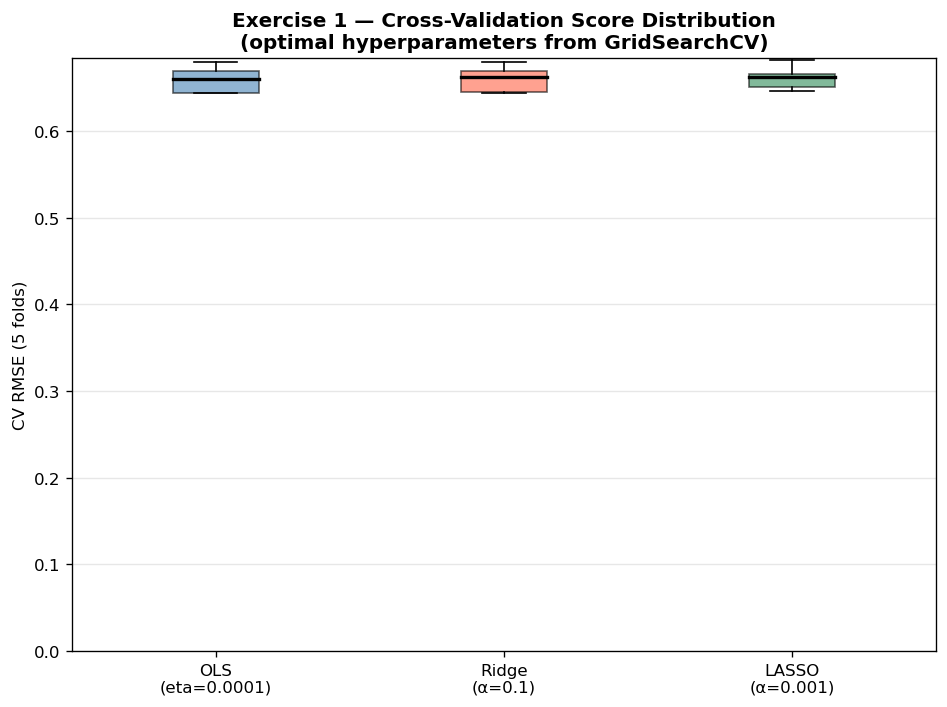

Saved: fig_ex1_boxplot.png


In [ ]:
best_ols   = SGDRegressor(penalty=None, learning_rate='constant',
                          eta0=best_eta, max_iter=1000,
                          random_state=42, tol=1e-4)
best_ridge = SGDRegressor(penalty='l2', alpha=best_alpha_ridge,
                          max_iter=1000, random_state=42, tol=1e-4)
best_lasso = SGDRegressor(penalty='l1', alpha=best_alpha_lasso,
                          max_iter=1000, random_state=42, tol=1e-4)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_ols   = -cross_val_score(best_ols,   X_train, y_train,
                             cv=kf, scoring='neg_root_mean_squared_error')
cv_ridge = -cross_val_score(best_ridge, X_train, y_train,
                             cv=kf, scoring='neg_root_mean_squared_error')
cv_lasso = -cross_val_score(best_lasso, X_train, y_train,
                             cv=kf, scoring='neg_root_mean_squared_error')

print('5-fold CV RMSE scores per model:')
print(f'  OLS   (eta={best_eta}):          {np.round(cv_ols,   4)}  mean={cv_ols.mean():.4f}')
print(f'  Ridge (alpha={best_alpha_ridge}): {np.round(cv_ridge, 4)}  mean={cv_ridge.mean():.4f}')
print(f'  LASSO (alpha={best_alpha_lasso}): {np.round(cv_lasso, 4)}  mean={cv_lasso.mean():.4f}')


fig, ax = plt.subplots(figsize=(8, 6))

bp = ax.boxplot([cv_ols, cv_ridge, cv_lasso],
                labels=[f'OLS\n(eta={best_eta})',
                        f'Ridge\n(α={best_alpha_ridge})',
                        f'LASSO\n(α={best_alpha_lasso})'],
                patch_artist=True,
                medianprops=dict(color='black', linewidth=2))


colors = ['steelblue', 'tomato', 'seagreen']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax.set_ylabel('CV RMSE (5 folds)')
ax.set_title('Exercise 1 — Cross-Validation Score Distribution\n'
             '(optimal hyperparameters from GridSearchCV)',
             fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('fig_ex1_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_ex1_boxplot.png')


  Degree   1  →  Train RMSE: 0.9699
  Degree   2  →  Train RMSE: 0.9588
  Degree   7  →  Train RMSE: 0.9451
  Degree  10  →  Train RMSE: 0.9280
  Degree  16  →  Train RMSE: 0.9194
  Degree 100  →  Train RMSE: 0.9057


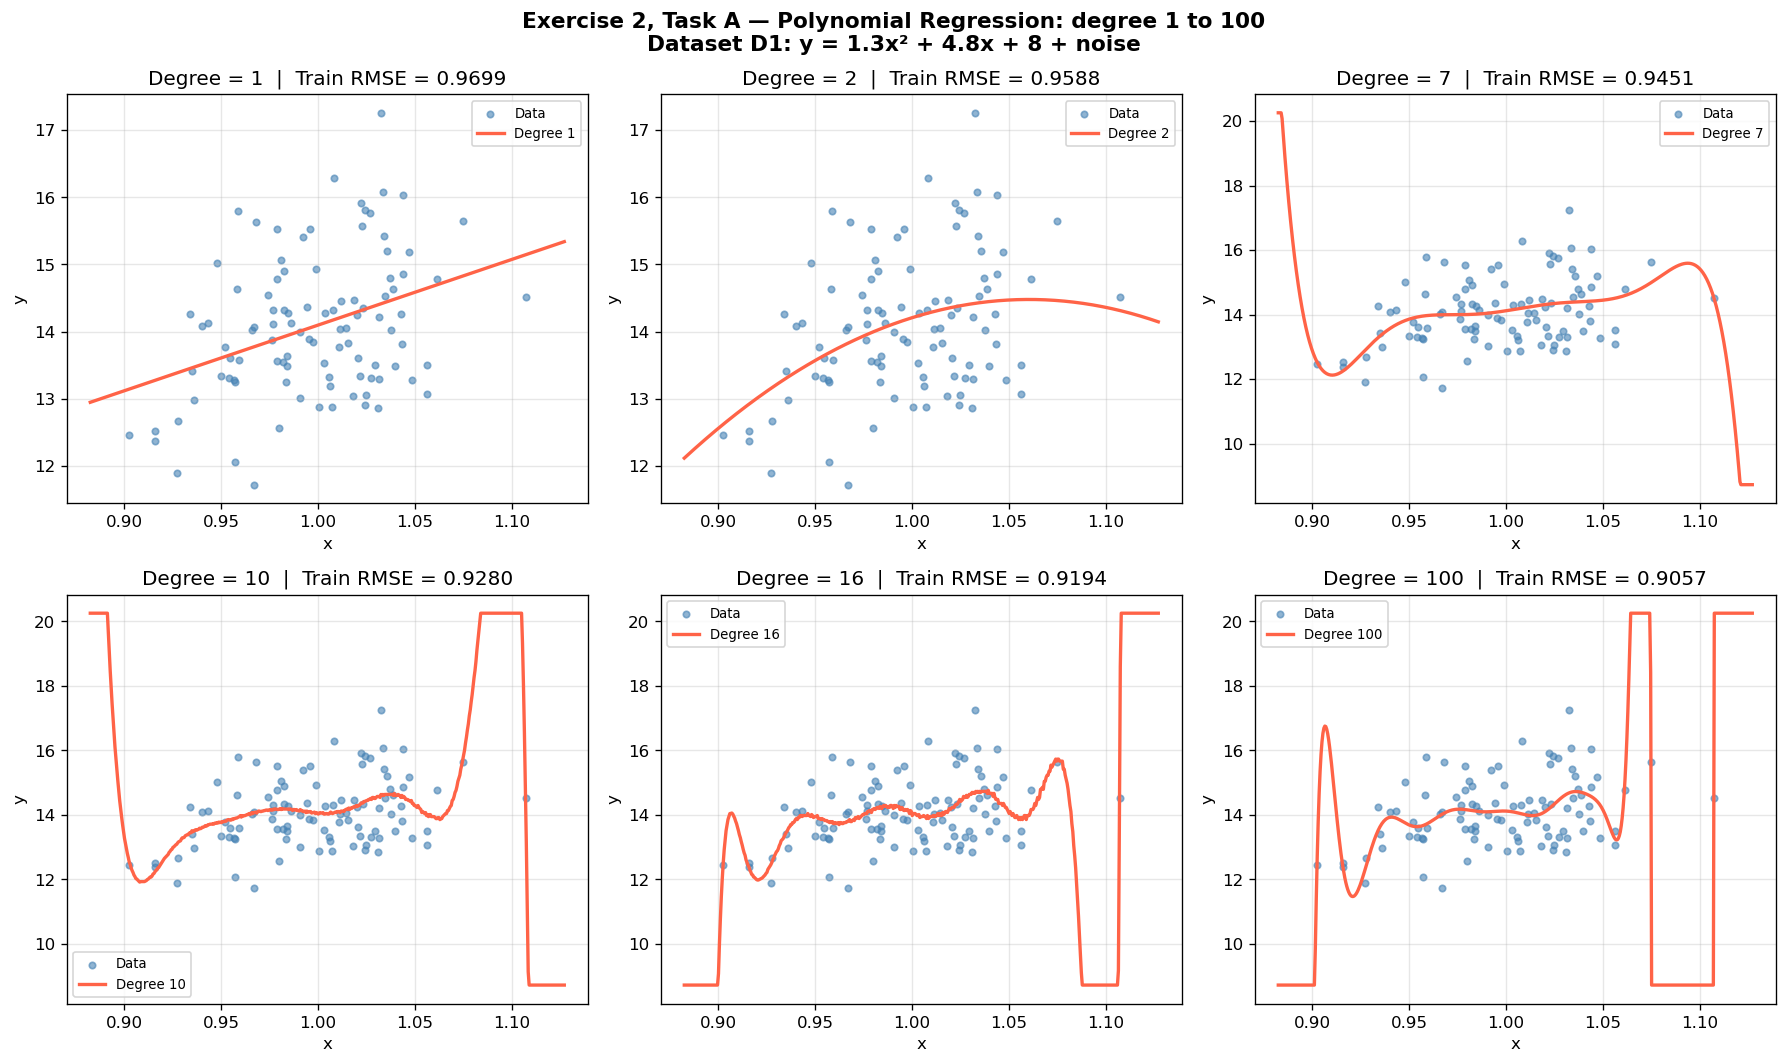


Saved: fig_ex2_poly_degrees.png


In [ ]:

degrees = [1, 2, 7, 10, 16, 100]


x_plot = np.linspace(x_D1.min() - 0.02, x_D1.max() + 0.02, 500).reshape(-1, 1)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle('Exercise 2, Task A — Polynomial Regression: degree 1 to 100\n'
             'Dataset D1: y = 1.3x² + 4.8x + 8 + noise',
             fontsize=13, fontweight='bold')

for ax, deg in zip(axes.flat, degrees):

    pipe = Pipeline([
        ('poly',  PolynomialFeatures(degree=deg, include_bias=False)),
        ('model', LinearRegression())
    ])
    pipe.fit(x_D1, y_D1.ravel())

    
    y_pred_plot = pipe.predict(x_plot)

    
    y_pred_plot = np.clip(y_pred_plot, y_D1.min() - 3, y_D1.max() + 3)

    
    train_rmse = np.sqrt(mean_squared_error(y_D1, pipe.predict(x_D1)))

    ax.scatter(x_D1, y_D1, color='steelblue', s=15, alpha=0.6, label='Data')
    ax.plot(x_plot, y_pred_plot, color='tomato', linewidth=2, label=f'Degree {deg}')
    ax.set_title(f'Degree = {deg}  |  Train RMSE = {train_rmse:.4f}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    print(f'  Degree {deg:3d}  →  Train RMSE: {train_rmse:.4f}')

plt.tight_layout()
plt.savefig('fig_ex2_poly_degrees.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nSaved: fig_ex2_poly_degrees.png')


  λ=0         →  Train RMSE: 0.9280
  λ=1e-06     →  Train RMSE: 0.9538
  λ=0.01      →  Train RMSE: 0.9625
  λ=1         →  Train RMSE: 0.9762


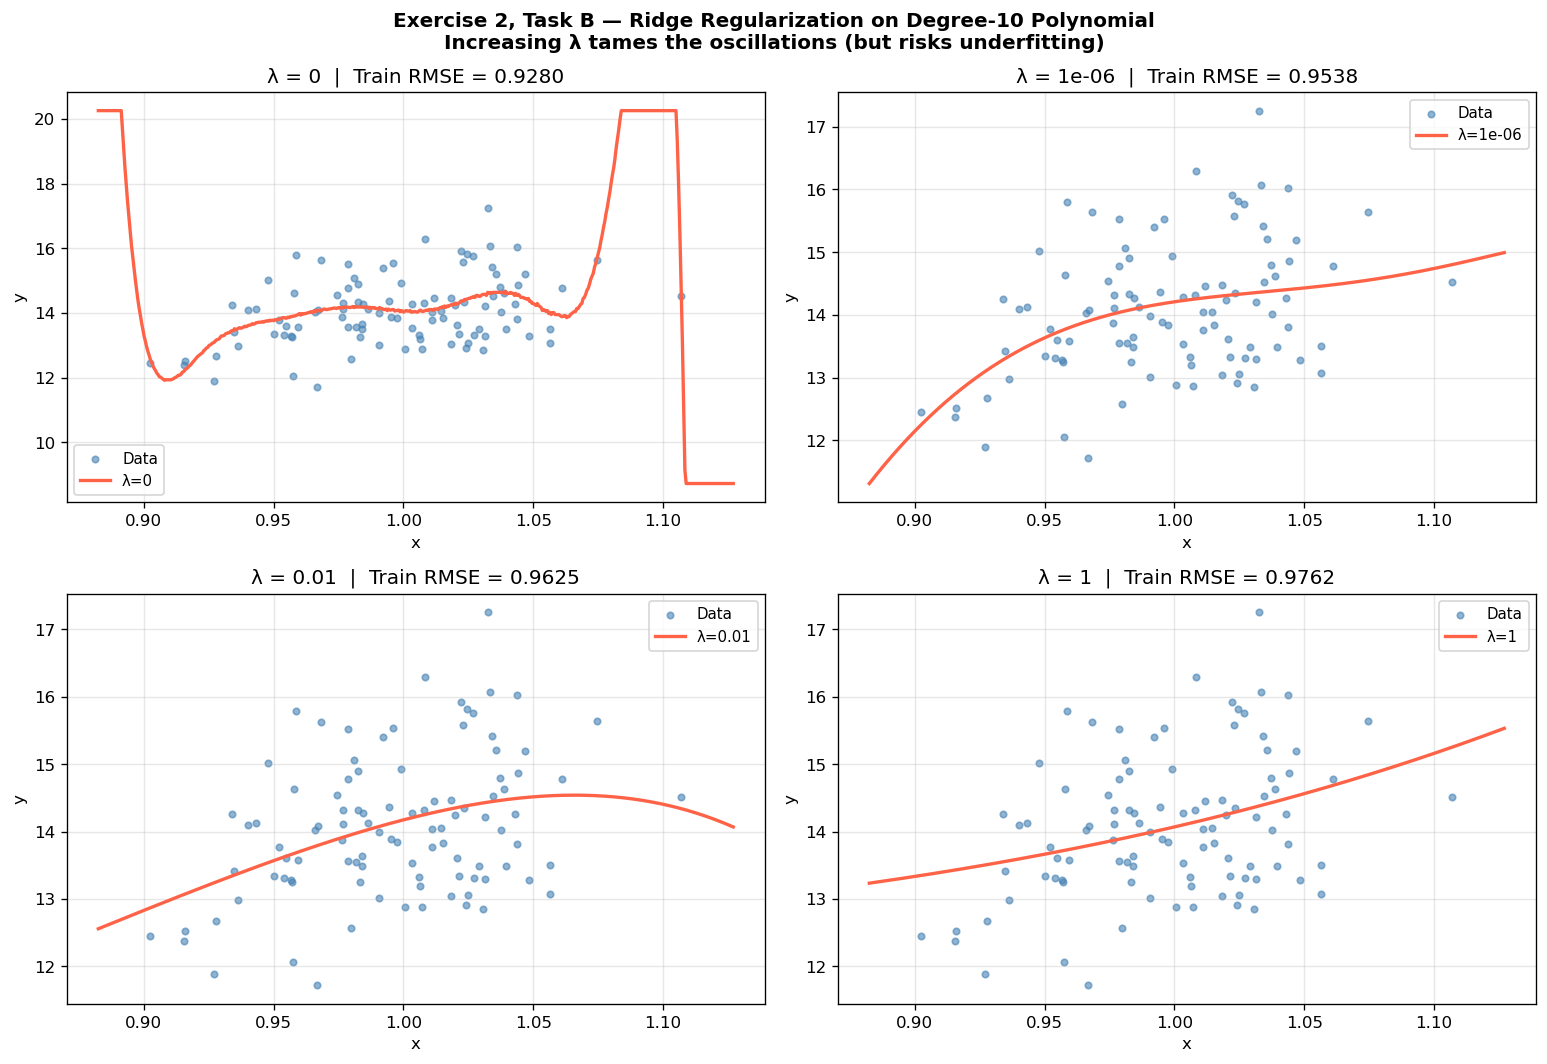


Saved: fig_ex2_ridge_regularization.png


In [ ]:

lambdas = [0, 1e-6, 1e-2, 1]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Exercise 2, Task B — Ridge Regularization on Degree-10 Polynomial\n'
             'Increasing λ tames the oscillations (but risks underfitting)',
             fontsize=12, fontweight='bold')

for ax, lam in zip(axes.flat, lambdas):

    
    if lam == 0:
        model = LinearRegression()
    else:
        model = Ridge(alpha=lam)

    pipe = Pipeline([
        ('poly',  PolynomialFeatures(degree=10, include_bias=False)),
        ('model', model)
    ])
    pipe.fit(x_D1, y_D1.ravel())

    y_pred_plot = pipe.predict(x_plot)
    y_pred_plot = np.clip(y_pred_plot, y_D1.min() - 3, y_D1.max() + 3)
    train_rmse  = np.sqrt(mean_squared_error(y_D1, pipe.predict(x_D1)))

    ax.scatter(x_D1, y_D1, color='steelblue', s=15, alpha=0.6, label='Data')
    ax.plot(x_plot, y_pred_plot, color='tomato', linewidth=2, label=f'λ={lam}')
    ax.set_title(f'λ = {lam}  |  Train RMSE = {train_rmse:.4f}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    print(f'  λ={lam:<8}  →  Train RMSE: {train_rmse:.4f}')

plt.tight_layout()
plt.savefig('fig_ex2_ridge_regularization.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nSaved: fig_ex2_ridge_regularization.png')


In [ ]:
X_en_train = np.hstack([np.ones((X_train.shape[0], 1)), X_train])
X_en_test  = np.hstack([np.ones((X_test.shape[0],  1)), X_test])

def elastic_net_sgd(X_tr, y_tr, X_te, y_te,
                    alpha=0.01, lam1=0.001, lam2=0.001,
                    batch_size=50, imax=200, epsilon=1e-6, seed=42):

    rng_l  = default_rng(seed)
    N, M   = X_tr.shape
    beta   = np.zeros(M)

    train_rmse_hist = []
    test_rmse_hist  = []

    for epoch in range(imax):
    
        idx    = rng_l.permutation(N)
        X_shuf = X_tr[idx]
        y_shuf = y_tr[idx]

        
        for b_start in range(0, N, batch_size):
            X_b = X_shuf[b_start : b_start + batch_size]
            y_b = y_shuf[b_start : b_start + batch_size]
            B   = X_b.shape[0]

            
            residuals = X_b @ beta - y_b
            g_data    = (1/B) * X_b.T @ residuals

            
            g_l2 = lam2 * beta

        
            g_l1 = lam1 * np.sign(beta)

            
            g  = g_data + g_l2 + g_l1

            
            g[0] = g_data[0]

            beta = beta - alpha * g

        
        train_rmse_hist.append(np.sqrt(np.mean((X_tr @ beta - y_tr) ** 2)))
        test_rmse_hist.append( np.sqrt(np.mean((X_te @ beta - y_te) ** 2)))

        # convergence check
        if epoch > 0 and abs(train_rmse_hist[-1] - train_rmse_hist[-2]) < epsilon:
            print(f'  Converged at epoch {epoch + 1}')
            break

    return beta, train_rmse_hist, test_rmse_hist

print('Elastic Net SGD ready.')
print(f'X_en_train shape: {X_en_train.shape}  (added bias column)')


Elastic Net SGD ready.
X_en_train shape: (1279, 12)  (added bias column)


=== Exercise 3: Elastic Net SGD — 4 combinations ===

  Converged at epoch 61
  (a) Both small
    Train RMSE: 0.6515  |  Test RMSE: 0.6252  |  Epochs: 61
  Converged at epoch 38
  (b) λ1=0 → pure Ridge
    Train RMSE: 0.6515  |  Test RMSE: 0.6248  |  Epochs: 38
  Converged at epoch 79
  (c) λ2=0 → pure LASSO
    Train RMSE: 0.6524  |  Test RMSE: 0.6264  |  Epochs: 79
  (d) Both large
    Train RMSE: 0.8006  |  Test RMSE: 0.8042  |  Epochs: 200


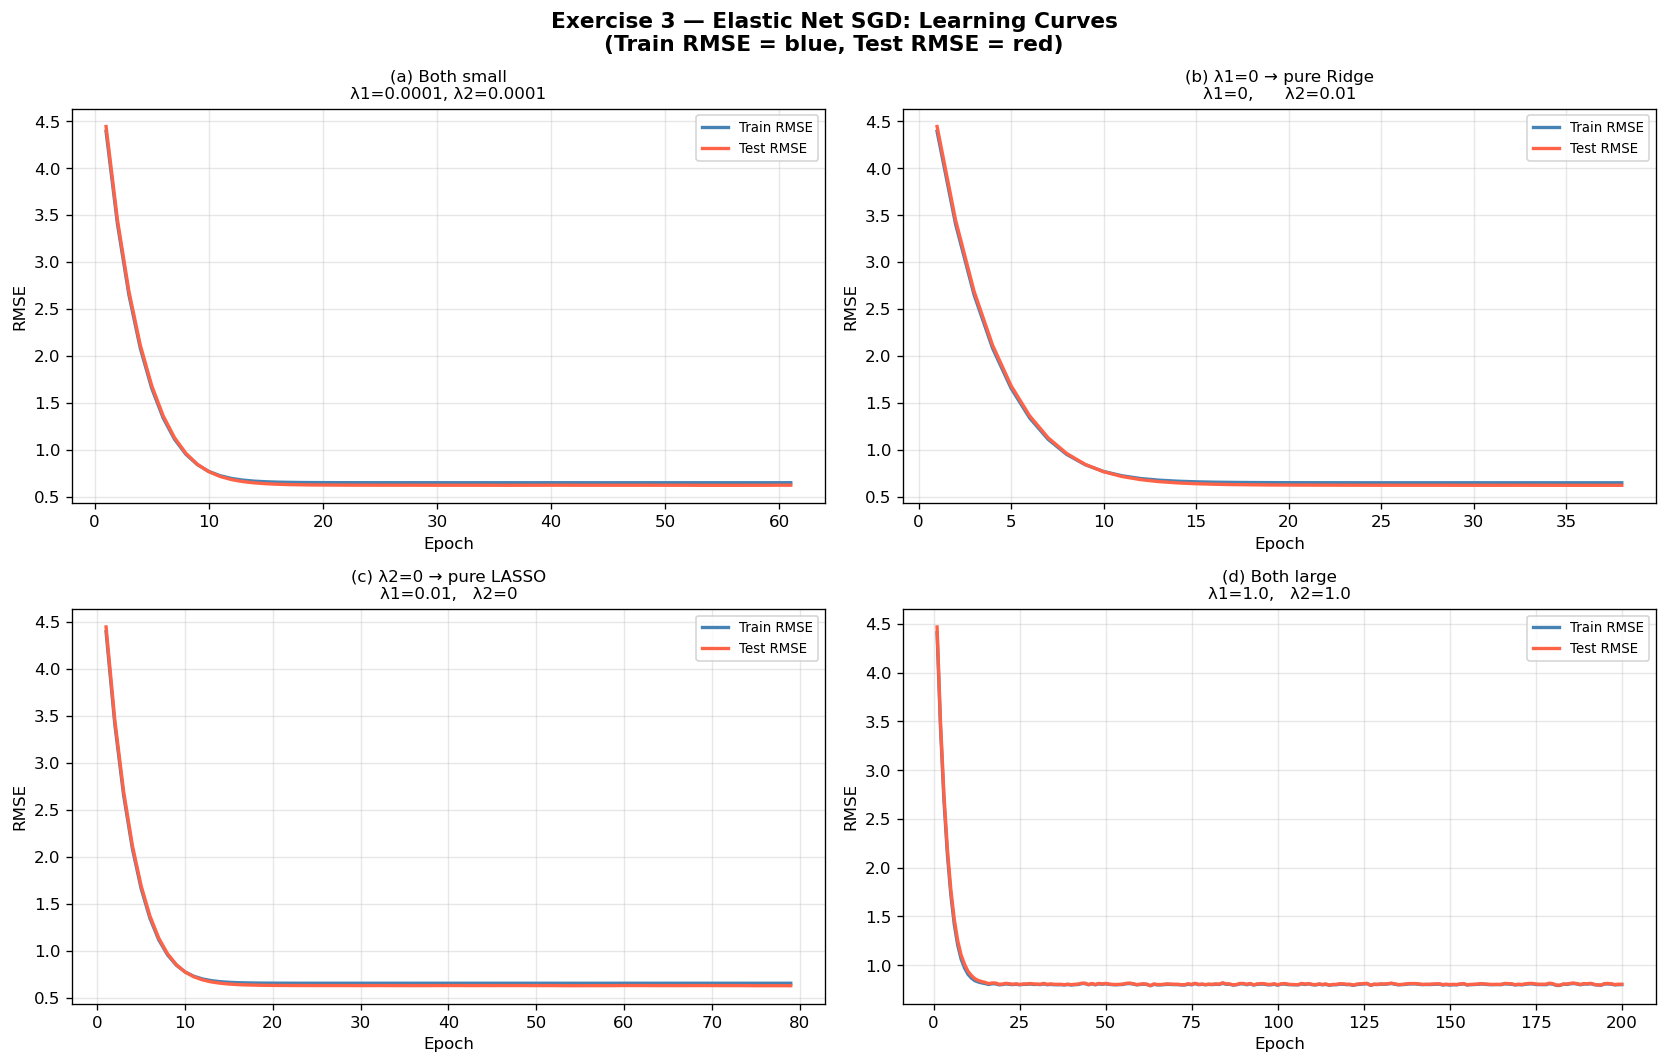


Saved: fig_ex3_elastic_net_curves.png


In [ ]:
configs = [
    {'label': '(a) Both small\nλ1=0.0001, λ2=0.0001', 'lam1': 0.0001, 'lam2': 0.0001},
    {'label': '(b) λ1=0 → pure Ridge\nλ1=0,      λ2=0.01',  'lam1': 0.0,   'lam2': 0.01},
    {'label': '(c) λ2=0 → pure LASSO\nλ1=0.01,   λ2=0',     'lam1': 0.01,  'lam2': 0.0},
    {'label': '(d) Both large\nλ1=1.0,   λ2=1.0',   'lam1': 1.0,   'lam2': 1.0},
]

print('=== Exercise 3: Elastic Net SGD — 4 combinations ===\n')

results_en = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Exercise 3 — Elastic Net SGD: Learning Curves\n'
             '(Train RMSE = blue, Test RMSE = red)',
             fontsize=13, fontweight='bold')

for ax, cfg in zip(axes.flat, configs):
    beta, tr, te = elastic_net_sgd(
        X_en_train, y_train, X_en_test, y_test,
        alpha=0.01, lam1=cfg['lam1'], lam2=cfg['lam2'],
        batch_size=50, imax=200, epsilon=1e-6
    )
    results_en[cfg['label']] = (beta, tr, te)

    epochs = range(1, len(tr) + 1)
    ax.plot(epochs, tr, color='steelblue', linewidth=2, label='Train RMSE')
    ax.plot(epochs, te, color='tomato',    linewidth=2, label='Test RMSE')
    ax.set_title(cfg['label'], fontsize=10)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('RMSE')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    print(f'  {cfg["label"].split(chr(10))[0]}')
    print(f'    Train RMSE: {tr[-1]:.4f}  |  Test RMSE: {te[-1]:.4f}  |  Epochs: {len(tr)}')

plt.tight_layout()
plt.savefig('fig_ex3_elastic_net_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nSaved: fig_ex3_elastic_net_curves.png')


In [ ]:

lam1_grid = [0.0, 0.001, 0.01, 0.1]
lam2_grid = [0.0, 0.001, 0.01, 0.1]

k        = 5
N_en     = X_en_train.shape[0]
rng_cv   = default_rng(42)
indices  = rng_cv.permutation(N_en)
fold_size = N_en // k

print('=== Exercise 3: Grid Search with 5-fold CV ===\n')
cv_scores = np.zeros((len(lam1_grid), len(lam2_grid)))

for i, lam1 in enumerate(lam1_grid):
    for j, lam2 in enumerate(lam2_grid):

        fold_rmses = []
        for fold in range(k):
            # carve out the validation fold
            val_start = fold * fold_size
            val_end   = val_start + fold_size if fold < k - 1 else N_en
            val_idx   = indices[val_start : val_end]
            tr_idx    = np.concatenate([indices[:val_start], indices[val_end:]])

            X_tr_f = X_en_train[tr_idx];  y_tr_f = y_train[tr_idx]
            X_va_f = X_en_train[val_idx]; y_va_f = y_train[val_idx]

            beta, _, _ = elastic_net_sgd(
                X_tr_f, y_tr_f, X_va_f, y_va_f,
                alpha=0.01, lam1=lam1, lam2=lam2,
                batch_size=50, imax=200, epsilon=1e-6, seed=42
            )
            val_rmse = np.sqrt(np.mean((X_va_f @ beta - y_va_f) ** 2))
            fold_rmses.append(val_rmse)

        cv_scores[i, j] = np.mean(fold_rmses)
        print(f'  λ1={lam1:.3f}  λ2={lam2:.3f}  →  CV RMSE: {cv_scores[i,j]:.4f}')
    print()

best_i, best_j = np.unravel_index(np.argmin(cv_scores), cv_scores.shape)
best_lam1 = lam1_grid[best_i]
best_lam2 = lam2_grid[best_j]
print(f'Best: λ1={best_lam1}, λ2={best_lam2}  →  CV RMSE={cv_scores[best_i, best_j]:.4f}')

beta_best, tr_best, te_best = elastic_net_sgd(
    X_en_train, y_train, X_en_test, y_test,
    alpha=0.01, lam1=best_lam1, lam2=best_lam2,
    batch_size=50, imax=200, epsilon=1e-6
)
print(f'\nFinal model (best λ): Train RMSE={tr_best[-1]:.4f}  Test RMSE={te_best[-1]:.4f}')


=== Exercise 3: Grid Search with 5-fold CV ===

  Converged at epoch 66
  Converged at epoch 69
  Converged at epoch 36
  Converged at epoch 49
  Converged at epoch 42
  λ1=0.000  λ2=0.000  →  CV RMSE: 0.6563
  Converged at epoch 66
  Converged at epoch 69
  Converged at epoch 36
  Converged at epoch 53
  Converged at epoch 53
  λ1=0.000  λ2=0.001  →  CV RMSE: 0.6564
  Converged at epoch 55
  Converged at epoch 38
  Converged at epoch 42
  Converged at epoch 56
  Converged at epoch 134
  λ1=0.000  λ2=0.010  →  CV RMSE: 0.6569
  Converged at epoch 44
  Converged at epoch 61
  Converged at epoch 157
  Converged at epoch 65
  λ1=0.000  λ2=0.100  →  CV RMSE: 0.6573

  Converged at epoch 55
  Converged at epoch 53
  Converged at epoch 45
  Converged at epoch 53
  Converged at epoch 53
  λ1=0.001  λ2=0.000  →  CV RMSE: 0.6568
  Converged at epoch 55
  Converged at epoch 53
  Converged at epoch 45
  Converged at epoch 63
  Converged at epoch 104
  λ1=0.001  λ2=0.001  →  CV RMSE: 0.6570
  Conv

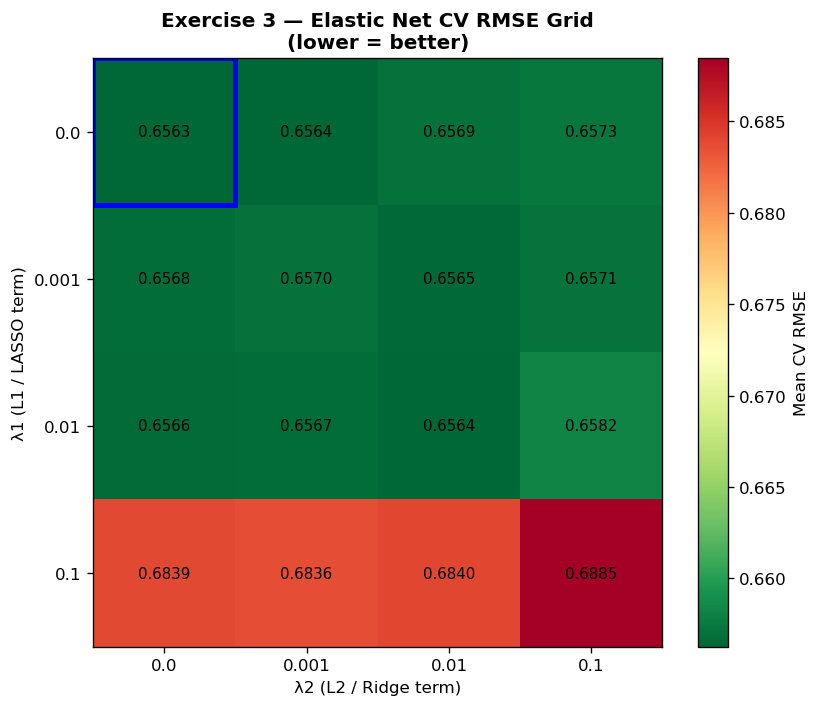

Saved: fig_ex3_cv_heatmap.png
Best: λ1=0.0, λ2=0.0  →  CV RMSE=0.6563


In [ ]:
# ── Exercise 3, Question 5: Heatmap of CV results 

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cv_scores, cmap='RdYlGn_r', aspect='auto')
plt.colorbar(im, ax=ax, label='Mean CV RMSE')

ax.set_xticks(range(len(lam2_grid)))
ax.set_yticks(range(len(lam1_grid)))
ax.set_xticklabels([str(v) for v in lam2_grid])
ax.set_yticklabels([str(v) for v in lam1_grid])
ax.set_xlabel('λ2 (L2 / Ridge term)')
ax.set_ylabel('λ1 (L1 / LASSO term)')
ax.set_title('Exercise 3 — Elastic Net CV RMSE Grid\n(lower = better)',
             fontweight='bold')


for i in range(len(lam1_grid)):
    for j in range(len(lam2_grid)):
        ax.text(j, i, f'{cv_scores[i,j]:.4f}',
                ha='center', va='center', fontsize=9, color='black')


ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1,
                             fill=False, edgecolor='blue', linewidth=3))

plt.tight_layout()
plt.savefig('fig_ex3_cv_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: fig_ex3_cv_heatmap.png')
print(f'Best: λ1={best_lam1}, λ2={best_lam2}  →  CV RMSE={cv_scores[best_i, best_j]:.4f}')
